# Лабораторная работа: Многослойный перцептрон (MLP)

**Задача:** бинарная классификация опухолей молочной железы (Malignant / Benign) на основе числовых признаков.

**Датасет:** `breast-cancer.csv` — 569 наблюдений, 30 числовых признаков.

**Фреймворк:** PyTorch

---
## 0. Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)

import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cpu


---
## 1. Загрузка и первичный анализ данных

In [2]:
DATA_PATH = 'breast-cancer.csv'

df = pd.read_csv(DATA_PATH)
print(f'Размер датасета: {df.shape}')
df.head()

Размер датасета: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


In [5]:
print('Пропущенные значения:')
print(df.isnull().sum()[df.isnull().sum() > 0])
if df.isnull().sum().sum() == 0:
    print('Пропуски отсутствуют')

Пропущенные значения:
Series([], dtype: int64)
Пропуски отсутствуют


In [6]:
print('Распределение целевой переменной:')
print(df['diagnosis'].value_counts())
print(f'\nДоля классов:')
print(df['diagnosis'].value_counts(normalize=True).round(3))

Распределение целевой переменной:
diagnosis
B    357
M    212
Name: count, dtype: int64

Доля классов:
diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64


---
## 2. Визуализация данных

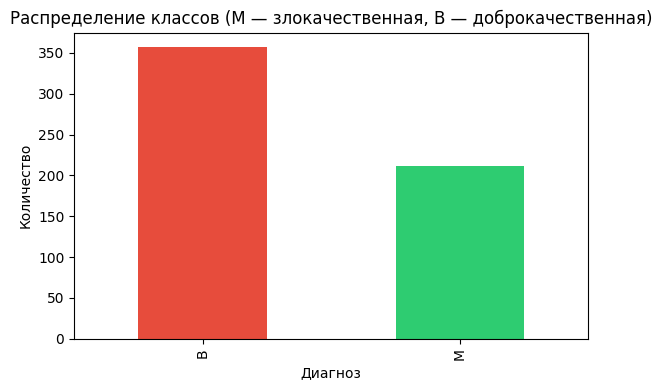

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
df['diagnosis'].value_counts().plot(kind='bar', color=['#e74c3c', '#2ecc71'], ax=ax)
ax.set_title('Распределение классов (M — злокачественная, B — доброкачественная)')
ax.set_xlabel('Диагноз')
ax.set_ylabel('Количество')
plt.tight_layout()
plt.show()

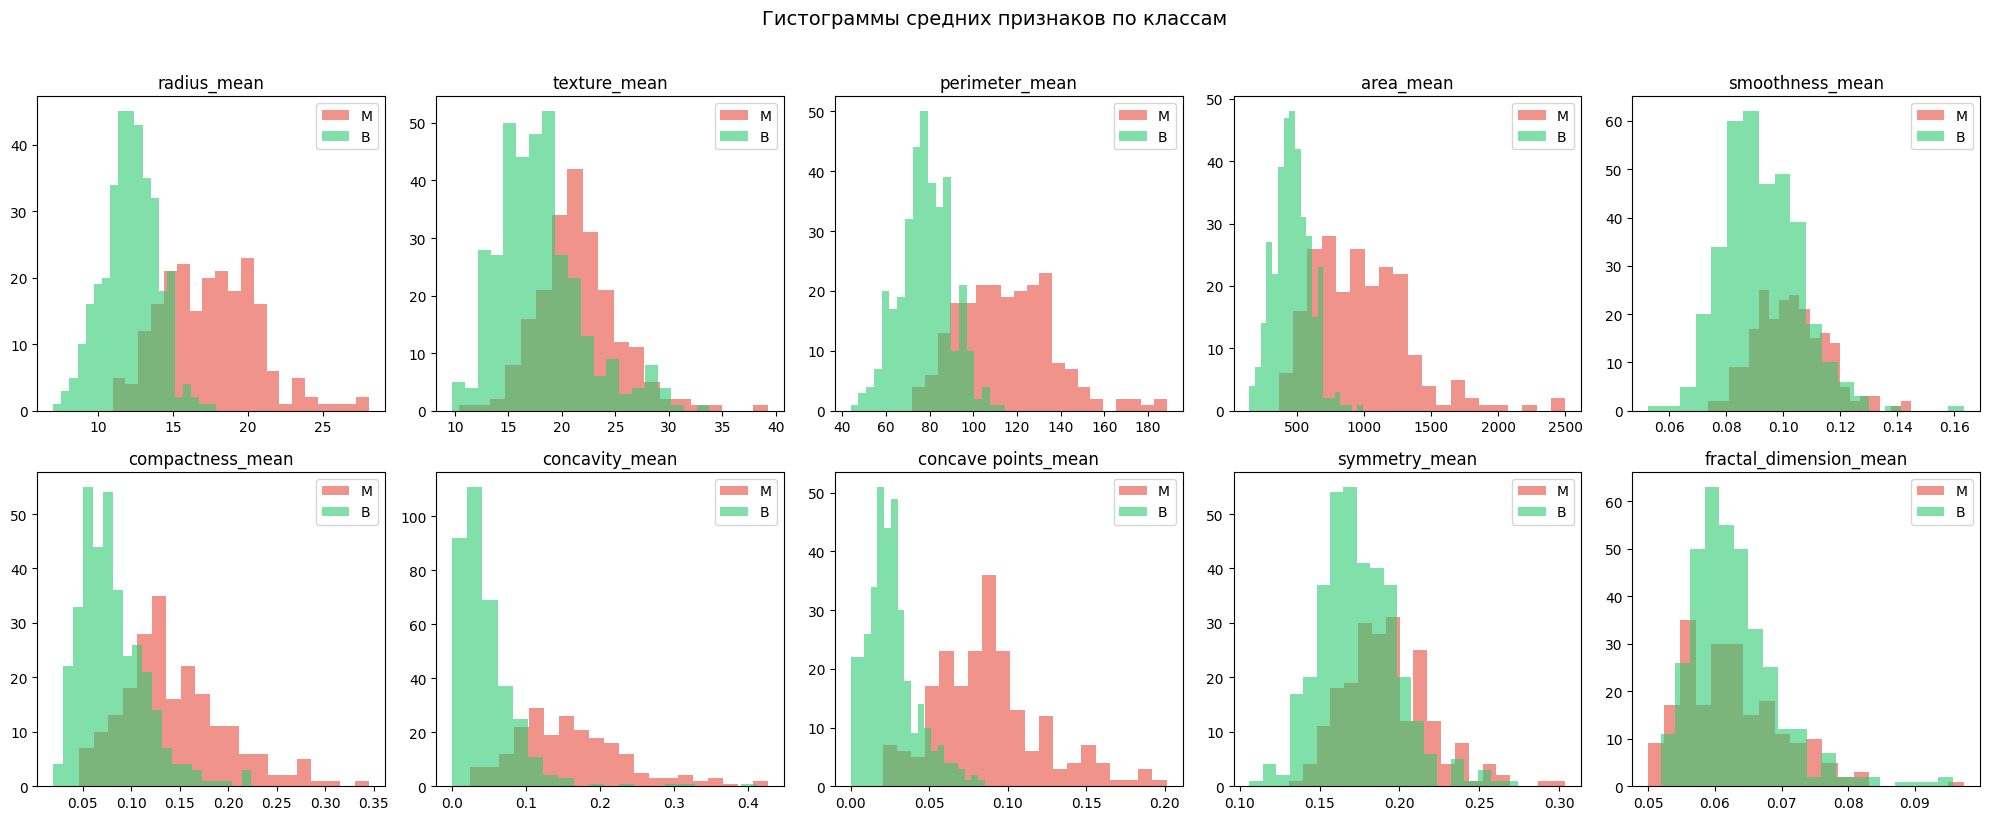

In [8]:
feature_cols = [c for c in df.columns if c not in ('id', 'diagnosis')]
mean_cols = [c for c in feature_cols if c.endswith('_mean')]

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.ravel(), mean_cols):
    for label, color in [('M', '#e74c3c'), ('B', '#2ecc71')]:
        subset = df[df['diagnosis'] == label]
        ax.hist(subset[col], bins=20, alpha=0.6, label=label, color=color)
    ax.set_title(col)
    ax.legend()
plt.suptitle('Гистограммы средних признаков по классам', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

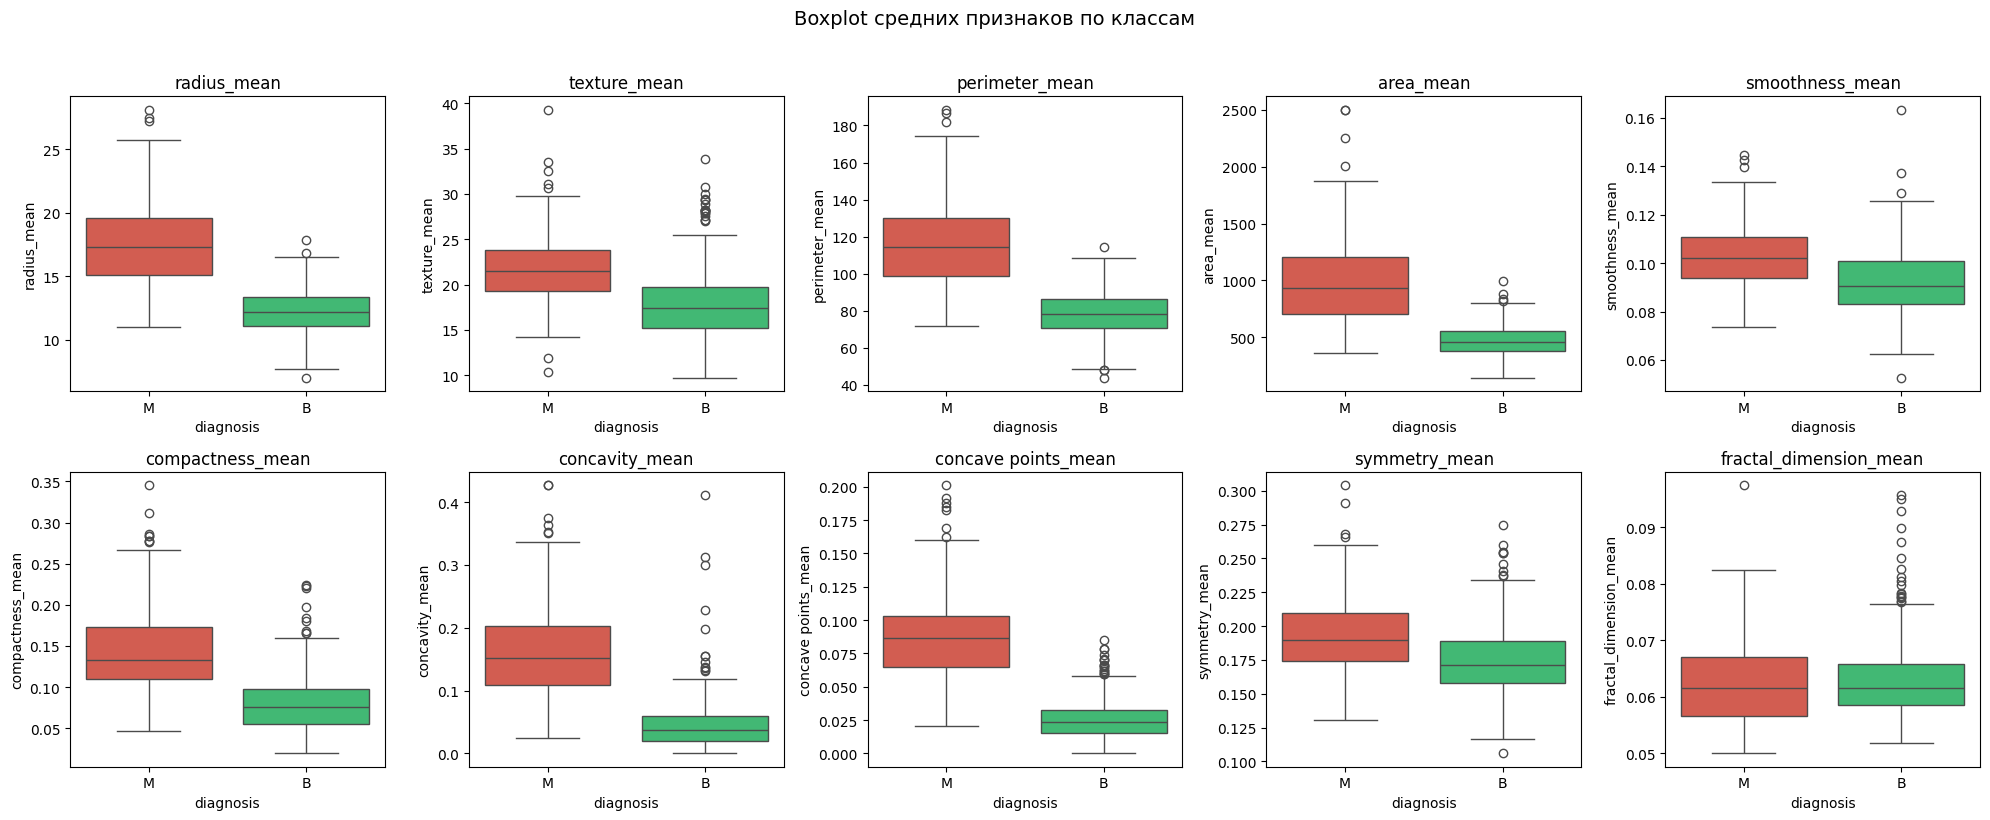

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.ravel(), mean_cols):
    sns.boxplot(x='diagnosis', y=col, data=df, ax=ax,
                palette={'M': '#e74c3c', 'B': '#2ecc71'})
    ax.set_title(col)
plt.suptitle('Boxplot средних признаков по классам', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

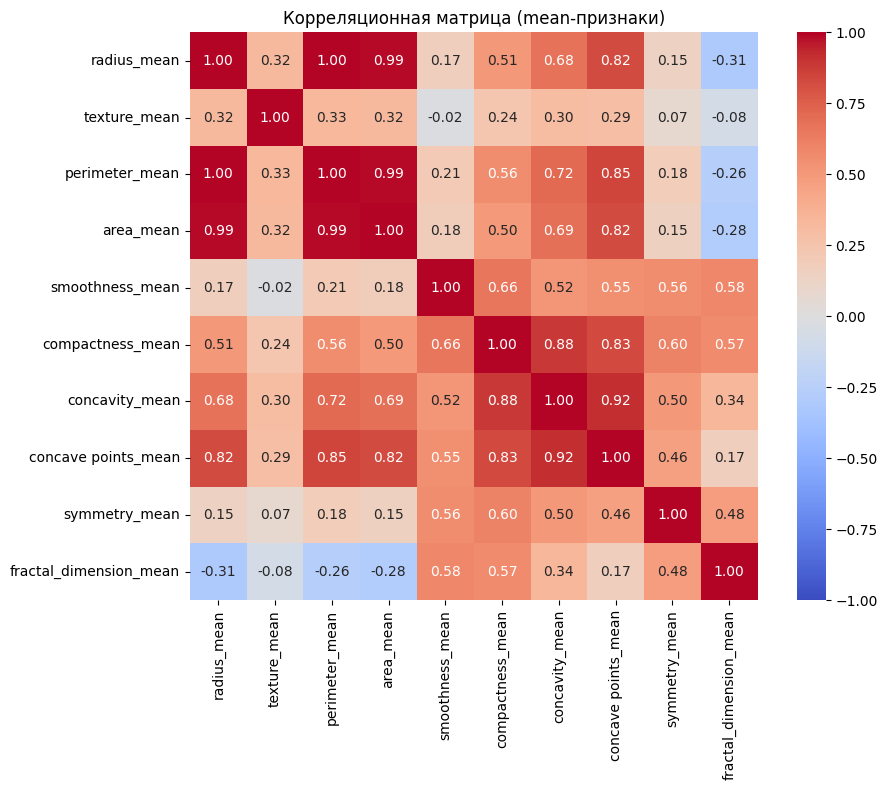

In [10]:
corr = df[mean_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax,
            vmin=-1, vmax=1, square=True)
ax.set_title('Корреляционная матрица (mean-признаки)')
plt.tight_layout()
plt.show()

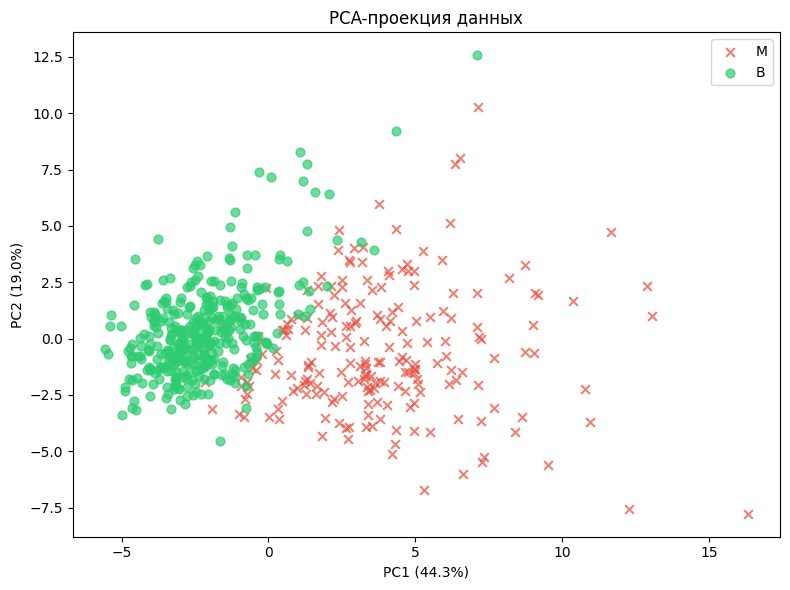

In [11]:
from sklearn.decomposition import PCA

scaler_pca = StandardScaler()
X_pca = scaler_pca.fit_transform(df[feature_cols])
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_pca)

fig, ax = plt.subplots(figsize=(8, 6))
for label, color, marker in [('M', '#e74c3c', 'x'), ('B', '#2ecc71', 'o')]:
    mask = df['diagnosis'] == label
    ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
               c=color, marker=marker, label=label, alpha=0.7, s=40)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_title('PCA-проекция данных')
ax.legend()
plt.tight_layout()
plt.show()

---
## 3. Предобработка и разделение данных

Разбиение: **train / validation / test = 60% / 20% / 20%**

- **train** — для обучения модели (подгонка весов);
- **validation** — для подбора гиперпараметров и ранней остановки (контроль переобучения);
- **test** — финальная, независимая оценка качества модели.

In [12]:
X = df[feature_cols].values
le = LabelEncoder()
y = le.fit_transform(df['diagnosis'])  # B=0, M=1

print(f'Классы: {le.classes_}  →  {list(range(len(le.classes_)))}')

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=SEED, stratify=y_train_val
)

print(f'Train: {X_train.shape[0]}, Val: {X_val.shape[0]}, Test: {X_test.shape[0]}')
print(f'Доля M в train: {y_train.mean():.3f}')
print(f'Доля M в val:   {y_val.mean():.3f}')
print(f'Доля M в test:  {y_test.mean():.3f}')

Классы: ['B' 'M']  →  [0, 1]
Train: 341, Val: 114, Test: 114
Доля M в train: 0.372
Доля M в val:   0.377
Доля M в test:  0.368


In [13]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

def to_tensors(X, y):
    return (
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    )

X_train_t, y_train_t = to_tensors(X_train, y_train)
X_val_t, y_val_t = to_tensors(X_val, y_val)
X_test_t, y_test_t = to_tensors(X_test, y_test)

BATCH_SIZE = 32

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=BATCH_SIZE
)
test_loader = DataLoader(
    TensorDataset(X_test_t, y_test_t),
    batch_size=BATCH_SIZE
)

---
## 4. Построение и обучение MLP

Архитектура: настраиваемый MLP с параметрами `hidden_sizes` (список размеров скрытых слоёв), `dropout_rate`.

In [14]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, output_dim=1, dropout_rate=0.3):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for h in hidden_sizes:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_rate))
            prev_dim = h
        layers.append(nn.Linear(prev_dim, output_dim))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [15]:
def train_model(model, train_loader, val_loader, epochs, lr, device):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            preds = (torch.sigmoid(logits) > 0.5).float()
            correct += (preds == yb).sum().item()
            total += yb.size(0)
        history['train_loss'].append(running_loss / total)
        history['train_acc'].append(correct / total)

        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                val_loss += loss.item() * xb.size(0)
                preds = (torch.sigmoid(logits) > 0.5).float()
                correct += (preds == yb).sum().item()
                total += yb.size(0)
        history['val_loss'].append(val_loss / total)
        history['val_acc'].append(correct / total)

    return history

In [16]:
INPUT_DIM = X_train.shape[1]
HIDDEN_SIZES = [64, 32]
EPOCHS = 100
LR = 1e-3

model = MLP(INPUT_DIM, HIDDEN_SIZES, dropout_rate=0.3)
print(model)
print(f'\nКоличество параметров: {sum(p.numel() for p in model.parameters()):,}')

MLP(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)

Количество параметров: 4,289


In [17]:
history = train_model(model, train_loader, val_loader, EPOCHS, LR, DEVICE)

### 4.1 Визуализация обучения и проверка переобучения

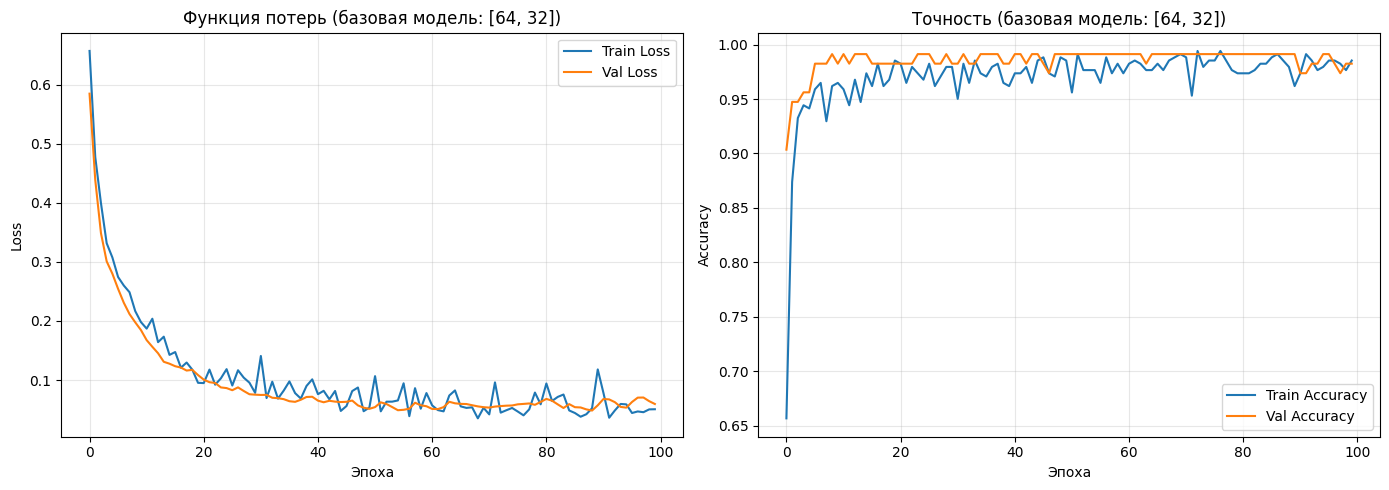

Train Acc: 0.9853
Val Acc:   0.9825
Разрыв (train - val): 0.0029
✓ Переобучение не выражено


In [18]:
def plot_history(history, title=''):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(history['train_loss'], label='Train Loss')
    ax1.plot(history['val_loss'], label='Val Loss')
    ax1.set_xlabel('Эпоха')
    ax1.set_ylabel('Loss')
    ax1.set_title(f'Функция потерь {title}')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(history['train_acc'], label='Train Accuracy')
    ax2.plot(history['val_acc'], label='Val Accuracy')
    ax2.set_xlabel('Эпоха')
    ax2.set_ylabel('Accuracy')
    ax2.set_title(f'Точность {title}')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    gap = history['train_acc'][-1] - history['val_acc'][-1]
    print(f'Train Acc: {history["train_acc"][-1]:.4f}')
    print(f'Val Acc:   {history["val_acc"][-1]:.4f}')
    print(f'Разрыв (train - val): {gap:.4f}')
    if gap > 0.05:
        print('⚠ Наблюдается переобучение (разрыв > 5%)')
    else:
        print('✓ Переобучение не выражено')

plot_history(history, '(базовая модель: [64, 32])')

### 4.2 Оценка на тестовой выборке

In [19]:
def evaluate_model(model, test_loader, device):
    model.eval()
    all_preds, all_probs, all_labels = [], [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            logits = model(xb)
            probs = torch.sigmoid(logits).cpu().numpy()
            preds = (probs > 0.5).astype(int)
            all_probs.extend(probs.flatten())
            all_preds.extend(preds.flatten())
            all_labels.extend(yb.numpy().flatten())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)

y_true, y_pred, y_prob = evaluate_model(model, test_loader, DEVICE)

print('=== Результаты на тестовой выборке ===')
print(f'Accuracy:  {accuracy_score(y_true, y_pred):.4f}')
print(f'Precision: {precision_score(y_true, y_pred):.4f}')
print(f'Recall:    {recall_score(y_true, y_pred):.4f}')
print(f'F1-score:  {f1_score(y_true, y_pred):.4f}')
print(f'ROC AUC:   {roc_auc_score(y_true, y_prob):.4f}')
print()
print(classification_report(y_true, y_pred, target_names=le.classes_))

=== Результаты на тестовой выборке ===
Accuracy:  0.9649
Precision: 0.9750
Recall:    0.9286
F1-score:  0.9512
ROC AUC:   0.9907

              precision    recall  f1-score   support

           B       0.96      0.99      0.97        72
           M       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



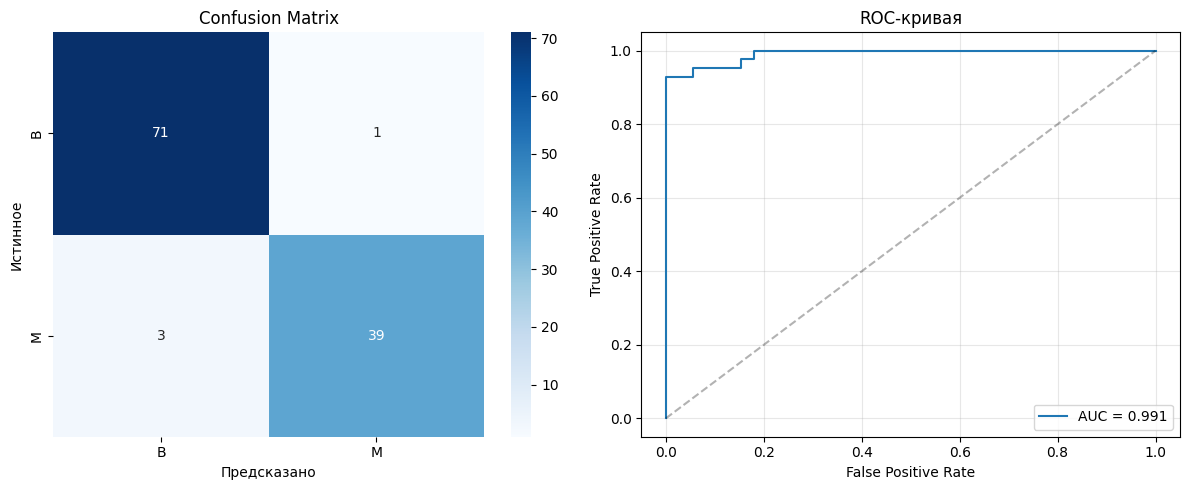

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax1)
ax1.set_xlabel('Предсказано')
ax1.set_ylabel('Истинное')
ax1.set_title('Confusion Matrix')

fpr, tpr, _ = roc_curve(y_true, y_prob)
ax2.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_true, y_prob):.3f}')
ax2.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('ROC-кривая')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 5. Исследование влияния глубины и ширины MLP

In [21]:
architectures = {
    'Shallow-Narrow [16]':          [16],
    'Shallow-Wide [128]':           [128],
    'Medium [64, 32]':              [64, 32],
    'Deep-Narrow [32, 16, 8]':      [32, 16, 8],
    'Deep-Wide [128, 64, 32]':      [128, 64, 32],
    'Very Deep [64, 32, 16, 8, 4]': [64, 32, 16, 8, 4],
}

results = {}

for name, hidden in architectures.items():
    torch.manual_seed(SEED)
    m = MLP(INPUT_DIM, hidden, dropout_rate=0.3)
    h = train_model(m, train_loader, val_loader, EPOCHS, LR, DEVICE)
    y_true_exp, y_pred_exp, y_prob_exp = evaluate_model(m, test_loader, DEVICE)
    acc = accuracy_score(y_true_exp, y_pred_exp)
    f1 = f1_score(y_true_exp, y_pred_exp)
    auc = roc_auc_score(y_true_exp, y_prob_exp)
    n_params = sum(p.numel() for p in m.parameters())
    results[name] = {
        'hidden': hidden,
        'params': n_params,
        'test_acc': acc,
        'test_f1': f1,
        'test_auc': auc,
        'history': h
    }
    print(f'{name:35s} | params={n_params:>6,} | acc={acc:.4f} | f1={f1:.4f} | auc={auc:.4f}')

Shallow-Narrow [16]                 | params=   545 | acc=0.9825 | f1=0.9756 | auc=0.9944


Shallow-Wide [128]                  | params= 4,353 | acc=0.9649 | f1=0.9512 | auc=0.9921


Medium [64, 32]                     | params= 4,289 | acc=0.9649 | f1=0.9512 | auc=0.9907


Deep-Narrow [32, 16, 8]             | params= 1,777 | acc=0.9737 | f1=0.9630 | auc=0.9970


Deep-Wide [128, 64, 32]             | params=14,785 | acc=0.9561 | f1=0.9398 | auc=0.9927


Very Deep [64, 32, 16, 8, 4]        | params= 5,017 | acc=0.9737 | f1=0.9639 | auc=0.9964


In [22]:
res_df = pd.DataFrame({
    k: {'Параметры': v['params'], 'Accuracy': v['test_acc'],
         'F1': v['test_f1'], 'AUC': v['test_auc']}
    for k, v in results.items()
}).T
res_df = res_df.sort_values('Accuracy', ascending=False)
print(res_df.to_string())

                              Параметры  Accuracy        F1       AUC
Shallow-Narrow [16]               545.0  0.982456  0.975610  0.994378
Deep-Narrow [32, 16, 8]          1777.0  0.973684  0.962963  0.997024
Very Deep [64, 32, 16, 8, 4]     5017.0  0.973684  0.963855  0.996362
Shallow-Wide [128]               4353.0  0.964912  0.951220  0.992063
Medium [64, 32]                  4289.0  0.964912  0.951220  0.990741
Deep-Wide [128, 64, 32]         14785.0  0.956140  0.939759  0.992725


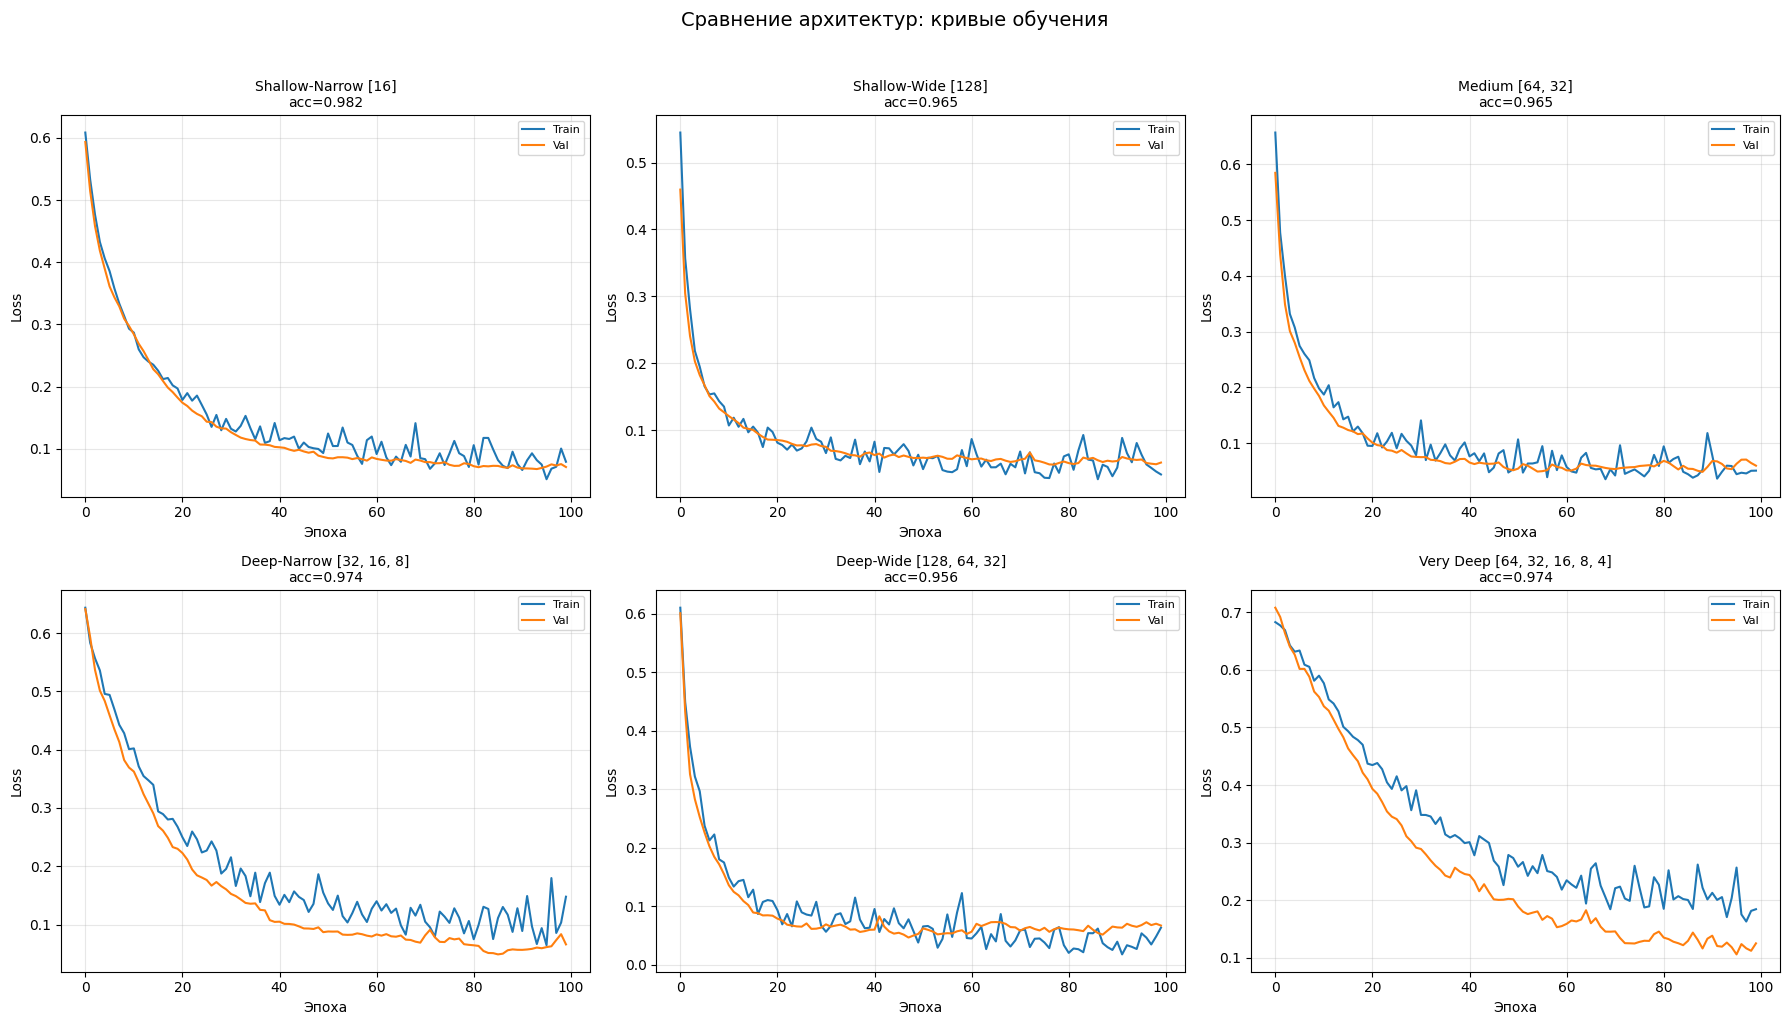

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, info) in zip(axes.ravel(), results.items()):
    h = info['history']
    ax.plot(h['train_loss'], label='Train')
    ax.plot(h['val_loss'], label='Val')
    ax.set_title(f'{name}\nacc={info["test_acc"]:.3f}', fontsize=10)
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('Loss')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
plt.suptitle('Сравнение архитектур: кривые обучения', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

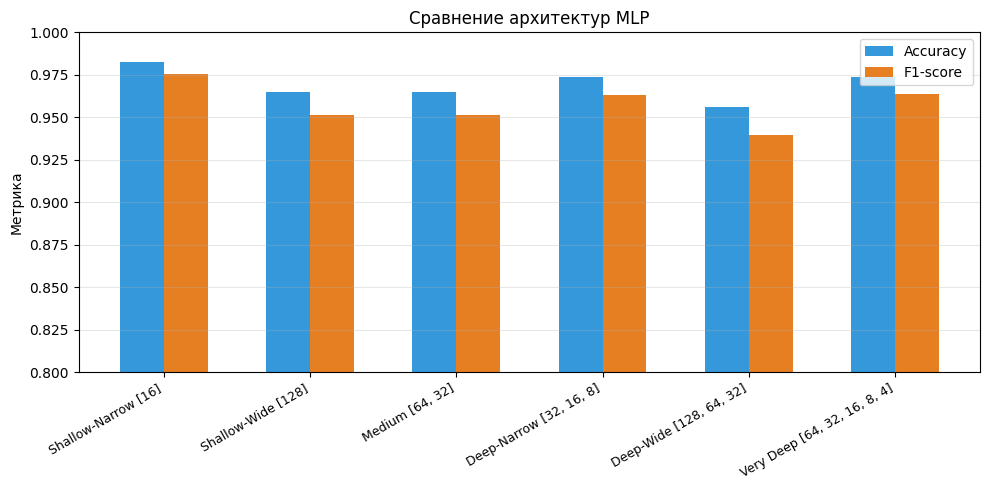

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
names = list(results.keys())
accs = [results[n]['test_acc'] for n in names]
f1s = [results[n]['test_f1'] for n in names]
x = np.arange(len(names))
ax.bar(x - 0.15, accs, 0.3, label='Accuracy', color='#3498db')
ax.bar(x + 0.15, f1s, 0.3, label='F1-score', color='#e67e22')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('Метрика')
ax.set_title('Сравнение архитектур MLP')
ax.legend()
ax.set_ylim(0.8, 1.0)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

---
## 6. Извлечение градиентов при инференсе

In [25]:
def extract_gradients(model, x_sample, device):
    """Извлекает градиенты для каждого линейного слоя при инференсе одного объекта."""
    model.eval()
    x = x_sample.clone().detach().unsqueeze(0).to(device)
    x.requires_grad_(True)

    activations = {}
    hooks = []

    def make_hook(name):
        def hook_fn(module, input, output):
            output.retain_grad()
            activations[name] = output
        return hook_fn

    for name, module in model.named_modules():
        if isinstance(module, nn.Linear):
            h = module.register_forward_hook(make_hook(name))
            hooks.append(h)

    output = model(x)
    output.backward()

    grads = {}
    for name, act in activations.items():
        if act.grad is not None:
            grads[name] = act.grad.detach().cpu().numpy().flatten()

    for h in hooks:
        h.remove()

    return grads, activations

In [26]:
sample_idx = 0
sample_x = X_test_t[sample_idx]
sample_label = y_test[sample_idx]
print(f'Выбран объект #{sample_idx}, истинный класс: {le.classes_[int(sample_label)]}')

grads, acts = extract_gradients(model, sample_x, DEVICE)

for layer_name, grad in grads.items():
    print(f'\nСлой: {layer_name}')
    print(f'  Размерность:       {grad.shape}')
    print(f'  Мин. градиент:     {grad.min():.6f}')
    print(f'  Макс. градиент:    {grad.max():.6f}')
    print(f'  Средний |градиент|: {np.abs(grad).mean():.6f}')

Выбран объект #0, истинный класс: B

Слой: network.0
  Размерность:       (64,)
  Мин. градиент:     -1.973763
  Макс. градиент:    2.674265
  Средний |градиент|: 0.445709

Слой: network.4
  Размерность:       (32,)
  Мин. градиент:     -0.844956
  Макс. градиент:    0.000000
  Средний |градиент|: 0.268751

Слой: network.8
  Размерность:       (1,)
  Мин. градиент:     1.000000
  Макс. градиент:    1.000000
  Средний |градиент|: 1.000000


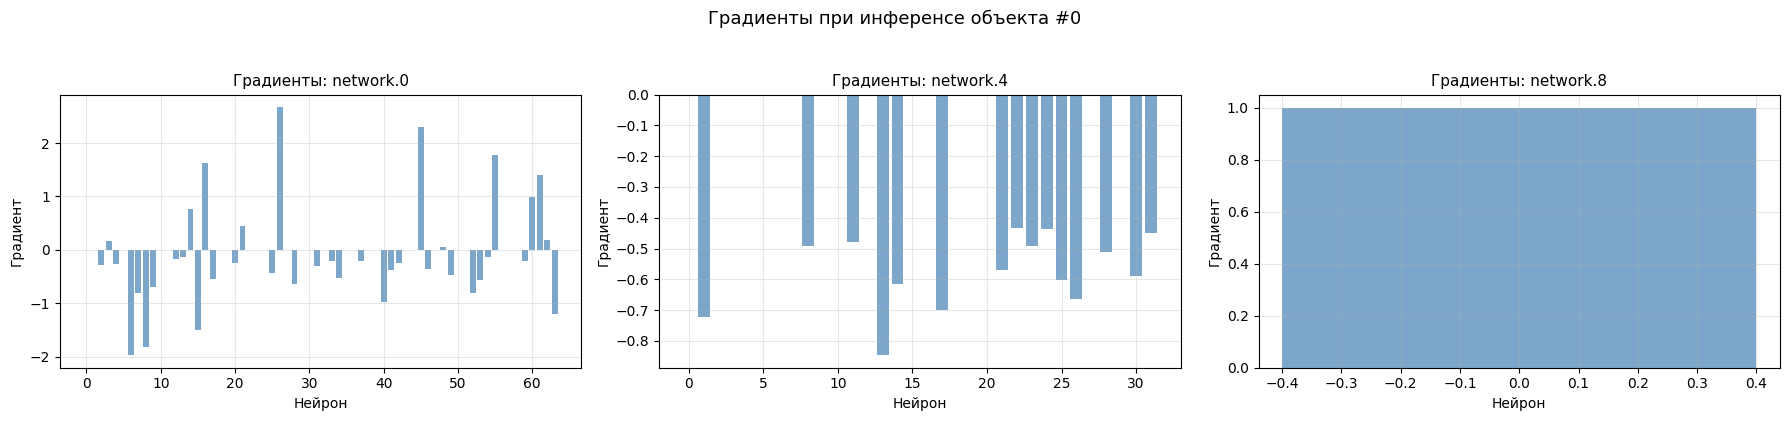

In [27]:
n_layers = len(grads)
fig, axes = plt.subplots(1, n_layers, figsize=(6 * n_layers, 4))
if n_layers == 1:
    axes = [axes]

for ax, (name, grad) in zip(axes, grads.items()):
    ax.bar(range(len(grad)), grad, color='steelblue', alpha=0.7)
    ax.set_title(f'Градиенты: {name}', fontsize=11)
    ax.set_xlabel('Нейрон')
    ax.set_ylabel('Градиент')
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Градиенты при инференсе объекта #{sample_idx}', fontsize=13, y=1.04)
plt.tight_layout()
plt.show()

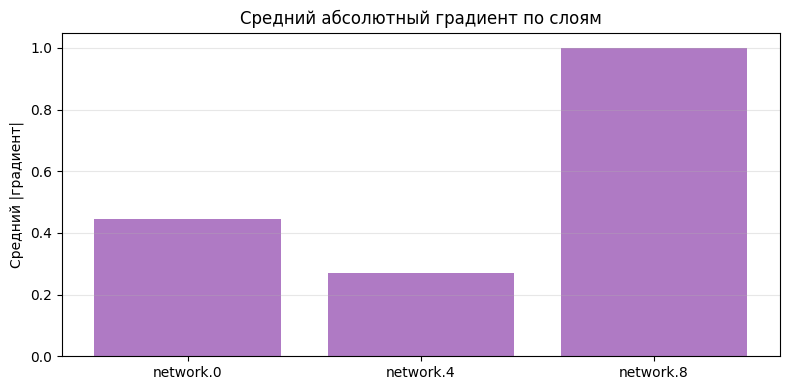

In [28]:
layer_names = list(grads.keys())
mean_abs_grads = [np.abs(grads[n]).mean() for n in layer_names]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(layer_names, mean_abs_grads, color='#9b59b6', alpha=0.8)
ax.set_ylabel('Средний |градиент|')
ax.set_title('Средний абсолютный градиент по слоям')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

---
## 7. Функции активации

Реализация основных функций активации на NumPy и их визуализация.

In [29]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

def leaky_relu(x, alpha=0.01):
    return np.where(x > 0, x, alpha * x)

def elu(x, alpha=1.0):
    return np.where(x > 0, x, alpha * (np.exp(x) - 1))

def swish(x):
    return x * sigmoid(x)

def softplus(x):
    return np.log(1 + np.exp(x))

def gelu(x):
    return 0.5 * x * (1 + np.tanh(np.sqrt(2 / np.pi) * (x + 0.044715 * x**3)))

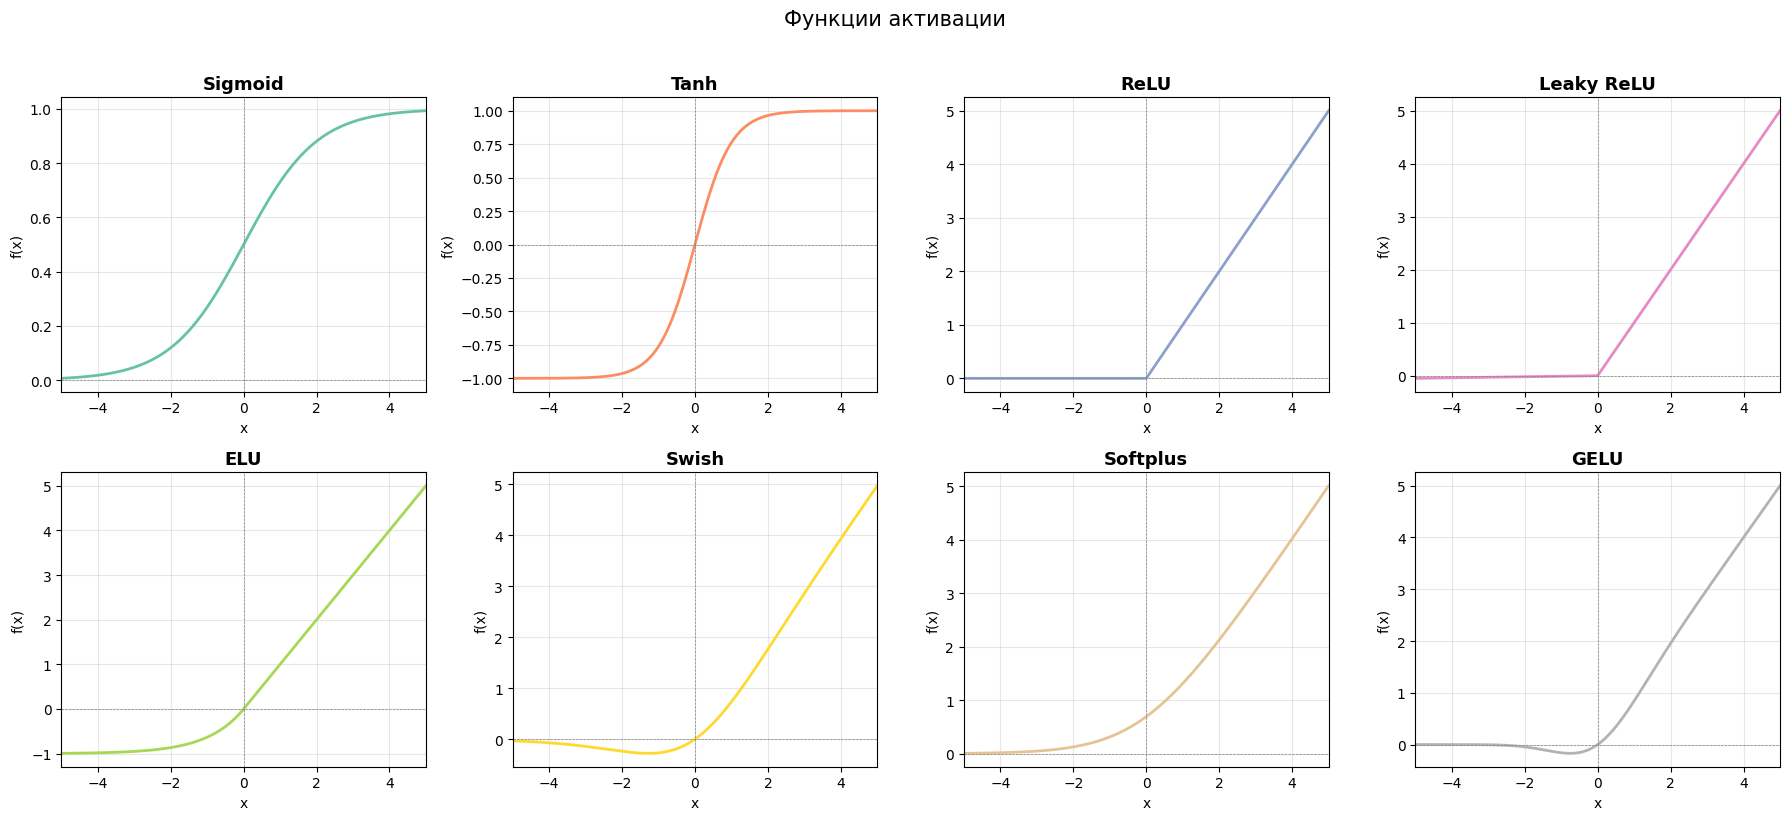

In [30]:
activations = {
    'Sigmoid':    sigmoid,
    'Tanh':       tanh,
    'ReLU':       relu,
    'Leaky ReLU': leaky_relu,
    'ELU':        elu,
    'Swish':      swish,
    'Softplus':   softplus,
    'GELU':       gelu,
}

x_range = np.linspace(-5, 5, 500)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
colors = plt.cm.Set2(np.linspace(0, 1, len(activations)))

for ax, (name, func), color in zip(axes.ravel(), activations.items(), colors):
    y_vals = func(x_range)
    ax.plot(x_range, y_vals, color=color, linewidth=2)
    ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    ax.axvline(0, color='gray', linewidth=0.5, linestyle='--')
    ax.set_title(name, fontsize=13, fontweight='bold')
    ax.set_xlabel('x')
    ax.set_ylabel('f(x)')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-5, 5)

plt.suptitle('Функции активации', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [31]:
print('Проверка значений функций активации при x = [-2, -1, 0, 1, 2]:')
test_x = np.array([-2, -1, 0, 1, 2])
for name, func in activations.items():
    vals = func(test_x)
    print(f'{name:12s}: {np.round(vals, 4)}')

Проверка значений функций активации при x = [-2, -1, 0, 1, 2]:
Sigmoid     : [0.1192 0.2689 0.5    0.7311 0.8808]
Tanh        : [-0.964  -0.7616  0.      0.7616  0.964 ]
ReLU        : [0 0 0 1 2]
Leaky ReLU  : [-0.02 -0.01  0.    1.    2.  ]
ELU         : [-0.8647 -0.6321  0.      1.      2.    ]
Swish       : [-0.2384 -0.2689  0.      0.7311  1.7616]
Softplus    : [0.1269 0.3133 0.6931 1.3133 2.1269]
GELU        : [-0.0454 -0.1588  0.      0.8412  1.9546]


---
## Выводы

1. **Датасет** содержит 569 наблюдений с 30 числовыми признаками, задача — бинарная классификация опухолей.
2. **Визуализация** показала, что классы разделимы по ряду признаков (radius, concavity, area), а некоторые признаки сильно коррелируют.
3. **Разбиение** 60/20/20 с сохранением пропорций классов (`stratify`) обеспечивает репрезентативность выборок.
4. **Базовый MLP [64, 32]** достигает высокого качества; кривые обучения позволяют выявить переобучение.
5. **Исследование архитектур** показало, что для данной задачи достаточно 1–2 скрытых слоёв; чрезмерная глубина не даёт преимущества.
6. **Градиенты** позволяют оценить вклад каждого слоя и нейрона в предсказание.
7. **Функции активации** реализованы на NumPy и визуализированы.